# PesaPap Growth Analytics

This notebook regenerates the CSV files using the unchanged seeded data generator, builds `pesapap.db` from those CSV files, runs the validation query and SQL questions A–H, and evaluates growth KPIs, RFM segments, signup cohorts, and the onboarding experiment. Run all cells from top to bottom from the repository root.

In [1]:
from pathlib import Path
import sqlite3
import subprocess
import sys

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, chisquare, norm
from IPython.display import display

# Regenerate the assignment data from its unchanged, seeded generator.
subprocess.run([sys.executable, "generate_data.py"], check=True)

users = pd.read_csv("users.csv", parse_dates=["signup_date"])
transactions = pd.read_csv("transactions.csv", parse_dates=["txn_date"])
experiment = pd.read_csv("experiment.csv")

print(f"Users: {len(users):,}; transactions: {len(transactions):,}; experiment assignments: {len(experiment):,}")

Files created successfully
Users: 3,000; transactions: 12,000; experiment assignments: 3,000


## Database and SQL analysis

In [2]:
conn = sqlite3.connect("pesapap.db")
for table_name, frame in [("users", users), ("transactions", transactions), ("experiment", experiment)]:
    frame.to_sql(table_name, conn, if_exists="replace", index=False)

print("Created pesapap.db from users.csv, transactions.csv, and experiment.csv.")

sql_text = Path("sql/queries.sql").read_text(encoding="utf-8")
sql_statements = [statement.strip() for statement in sql_text.split(";") if statement.strip()]
query_labels = ["Validation"] + [f"Question {letter}" for letter in "ABCDEFGH"]
if len(sql_statements) != len(query_labels):
    raise ValueError(f"Expected {len(query_labels)} SQL statements, found {len(sql_statements)}")

query_results = {}
for label, statement in zip(query_labels, sql_statements, strict=True):
    query_results[label] = pd.read_sql(statement, conn)
    print(f"{label}: {len(query_results[label]):,} result row(s)")
    display(query_results[label].head(10) if label == "Validation" else query_results[label])

Created pesapap.db from users.csv, transactions.csv, and experiment.csv.
Validation: 3,737 result row(s)


,txn_id,user_id,signup_date,txn_date,product,amount
0,1582,2,2026-04-05 00:00:00,2026-03-27 00:00:00,Send Money,136.0
1,3492,2,2026-04-05 00:00:00,2026-04-01 00:00:00,Airtime,292.0
2,9694,2,2026-04-05 00:00:00,2026-04-01 00:00:00,Airtime,878.0
3,4898,3,2026-03-18 00:00:00,2026-01-25 00:00:00,Send Money,310.0
4,7505,3,2026-03-18 00:00:00,2026-02-10 00:00:00,Send Money,1209.0
5,1006,4,2026-03-08 00:00:00,2026-01-22 00:00:00,Bill Pay,2699.0
6,6463,4,2026-03-08 00:00:00,2026-01-25 00:00:00,Send Money,823.0
7,3596,7,2026-04-14 00:00:00,2026-02-03 00:00:00,Send Money,3172.0
8,5745,7,2026-04-14 00:00:00,2026-04-03 00:00:00,Send Money,961.0
9,3131,8,2026-02-10 00:00:00,2026-01-20 00:00:00,Bill Pay,664.0


Question A: 1 result row(s)


,total_users
0,3000


Question B: 1 result row(s)


,total_transaction_value
0,15979309.0


... (8 outputs left out)

Question G: 6 result row(s)


,month,transaction_value,previous_transaction_value,growth_percent
0,2026-01,1733121.0,NaN,NaN
1,2026-02,2993105.0,1733121.0,72.70
2,2026-03,3199125.0,2993105.0,6.88
3,2026-04,3262447.0,3199125.0,1.98
4,2026-05,3365002.0,3262447.0,3.14
5,2026-06,1426509.0,3365002.0,-57.61


Question H: 6 result row(s)


,month,active_users,previous_active_users,returning_users,retention_percent
0,2026-01,1055,NaN,0,NaN
1,2026-02,1596,1055.0,555,52.61
2,2026-03,1649,1596.0,859,53.82
3,2026-04,1704,1649.0,945,57.31
4,2026-05,1690,1704.0,976,57.28
5,2026-06,907,1690.0,516,30.53


### Signup-date validation

A transaction dated before its user's signup date is logically inconsistent. The validation query returns each affected transaction row. We retain all transactions in the overall SQL/KPI results so the reported source totals are reproducible, but exclude pre-signup rows from the cohort retention analysis because they cannot represent post-signup activity.

In [3]:
invalid_transactions = query_results["Validation"]
affected_users = invalid_transactions["user_id"].nunique()
invalid_user_pct = affected_users / users["user_id"].nunique() * 100
validation_summary = pd.DataFrame({
    "Measure": ["Invalid transaction rows", "Affected users", "Affected users (% of all users)"],
    "Value": [len(invalid_transactions), affected_users, round(invalid_user_pct, 2)],
})
display(validation_summary)

,Measure,Value
0,Invalid transaction rows,3737.0
1,Affected users,1749.0
2,Affected users (% of all users),58.3


## KPI scorecard

In [4]:
total_users = int(pd.read_sql("SELECT COUNT(*) AS value FROM users", conn).iloc[0, 0])
total_txn_value = float(pd.read_sql("SELECT SUM(amount) AS value FROM transactions", conn).iloc[0, 0])
avg_txn_value = float(pd.read_sql("SELECT AVG(amount) AS value FROM transactions", conn).iloc[0, 0])
total_transactions = int(pd.read_sql("SELECT COUNT(*) AS value FROM transactions", conn).iloc[0, 0])
conversion_rate = float(pd.read_sql("SELECT AVG(converted) * 100.0 AS value FROM experiment", conn).iloc[0, 0])

kpi_dictionary = pd.DataFrame([
    {"Name": "Total users", "Definition": "Number of registered users in the users table.", "Calculation": "COUNT(users.user_id)"},
    {"Name": "Total transaction value", "Definition": "Sum of the amount on every recorded transaction; includes flagged pre-signup rows.", "Calculation": "SUM(transactions.amount)"},
    {"Name": "Average transaction value", "Definition": "Mean amount per recorded transaction; includes flagged pre-signup rows.", "Calculation": "SUM(amount) / COUNT(txn_id)"},
    {"Name": "Total transactions", "Definition": "Number of recorded transaction rows; includes flagged pre-signup rows.", "Calculation": "COUNT(transactions.txn_id)"},
    {"Name": "Conversion rate", "Definition": "Percentage of assigned experiment users marked converted.", "Calculation": "100 * SUM(experiment.converted) / COUNT(experiment.user_id)"},
])
scorecard = pd.DataFrame([
    {"Metric": "Total users", "Value": total_users},
    {"Metric": "Total transaction value", "Value": round(total_txn_value, 2)},
    {"Metric": "Average transaction value", "Value": round(avg_txn_value, 2)},
    {"Metric": "Total transactions", "Value": total_transactions},
    {"Metric": "Conversion rate (%)", "Value": round(conversion_rate, 2)},
])
print("Metric dictionary")
display(kpi_dictionary)
print("KPI scorecard")
display(scorecard)

Metric dictionary


,Name,Definition,Calculation
0,Total users,Number of registered users in the users table.,COUNT(users.user_id)
1,Total transaction value,Sum of the amount on every recorded transactio...,SUM(transactions.amount)
2,Average transaction value,Mean amount per recorded transaction; includes...,SUM(amount) / COUNT(txn_id)
3,Total transactions,Number of recorded transaction rows; includes ...,COUNT(transactions.txn_id)
4,Conversion rate,Percentage of assigned experiment users marked...,100 * SUM(experiment.converted) / COUNT(experi...


KPI scorecard


,Metric,Value
0,Total users,3000.00
1,Total transaction value,15979309.00
2,Average transaction value,1331.61
3,Total transactions,12000.00
4,Conversion rate (%),12.20


## RFM segmentation

RFM segments cover 2,943 users with at least one recorded transaction.

,Segment,Customers
0,Loyal Customers,749
1,Others,733
2,At Risk,727
3,Potential Loyalists,558
4,Champions,176


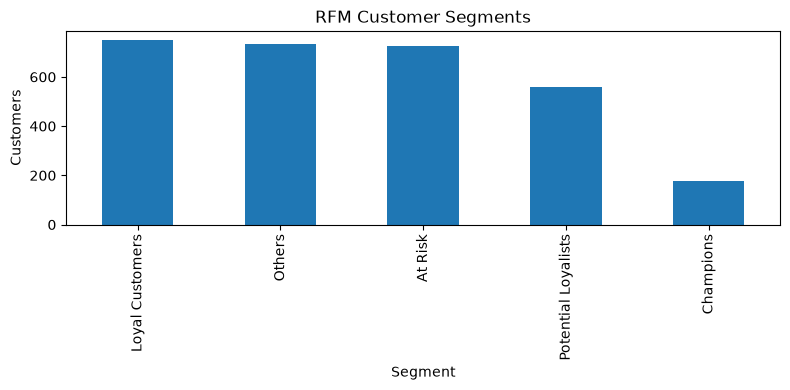

In [5]:
rfm_source = transactions.copy()
snapshot_date = rfm_source["txn_date"].max() + pd.Timedelta(days=1)
rfm = rfm_source.groupby("user_id").agg(
    Recency=("txn_date", lambda dates: (snapshot_date - dates.max()).days),
    Frequency=("txn_id", "count"),
    Monetary=("amount", "sum"),
)

rfm["R_Score"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

def segment_customer(row):
    if row["R_Score"] == row["F_Score"] == row["M_Score"] == 4:
        return "Champions"
    if row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    if row["R_Score"] >= 3:
        return "Potential Loyalists"
    if row["R_Score"] == 1:
        return "At Risk"
    return "Others"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
segment_counts = rfm["Segment"].value_counts().rename_axis("Segment").reset_index(name="Customers")
print(f"RFM segments cover {len(rfm):,} users with at least one recorded transaction.")
display(segment_counts)

import matplotlib.pyplot as plt
segment_counts.plot(kind="bar", x="Segment", y="Customers", legend=False, figsize=(8, 4))
plt.title("RFM Customer Segments")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

## Signup cohort retention

Cohort membership is based on signup month. A transaction before signup is excluded from this analysis. Retention for each period is active users divided by all users who signed up in that cohort month. Calendar periods after the last complete transaction month are explicitly marked `Incomplete`; elapsed periods with no activity are shown as 0%.

In [6]:
users["cohort_month"] = users["signup_date"].dt.to_period("M")
cohort_sizes = users.groupby("cohort_month")["user_id"].nunique()
cohort_activity = transactions.merge(
    users[["user_id", "signup_date", "cohort_month"]], on="user_id", how="inner"
)
cohort_activity = cohort_activity.loc[cohort_activity["txn_date"] >= cohort_activity["signup_date"]].copy()
cohort_activity["txn_month"] = cohort_activity["txn_date"].dt.to_period("M")
cohort_activity["cohort_index"] = (
    (cohort_activity["txn_month"].dt.year - cohort_activity["cohort_month"].dt.year) * 12
    + cohort_activity["txn_month"].dt.month - cohort_activity["cohort_month"].dt.month
)
cohort_activity = cohort_activity.loc[cohort_activity["cohort_index"] >= 0]
active_counts = cohort_activity.groupby(["cohort_month", "cohort_index"])["user_id"].nunique()
latest_observed_month = transactions["txn_date"].max().to_period("M")
latest_complete_month = latest_observed_month - 1
max_index = max((latest_observed_month - cohort).n for cohort in cohort_sizes.index)

retention_rows = []
for cohort, cohort_size in cohort_sizes.items():
    row = {"Cohort": str(cohort), "Cohort users": int(cohort_size)}
    for index in range(max_index + 1):
        period_month = cohort + index
        if period_month > latest_complete_month:
            row[f"Month {index}"] = "Incomplete"
        else:
            active = int(active_counts.get((cohort, index), 0))
            row[f"Month {index}"] = round(active / cohort_size * 100, 2)
    retention_rows.append(row)
cohort_retention = pd.DataFrame(retention_rows).set_index("Cohort")
print(f"Last observed transaction month: {latest_observed_month}; latest complete month: {latest_complete_month}.")
display(cohort_retention)

Last observed transaction month: 2026-06; latest complete month: 2026-05.


,Cohort users,Month 0,Month 1,Month 2,Month 3,Month 4,Month 5
Cohort,,,,,,,
2026-01,773,24.71,53.69,55.89,58.34,56.02,Incomplete
2026-02,703,29.87,54.91,54.62,59.03,Incomplete,Incomplete
2026-03,745,32.48,55.44,56.91,Incomplete,Incomplete,Incomplete
2026-04,779,34.92,53.66,Incomplete,Incomplete,Incomplete,Incomplete


## Onboarding experiment

**H₀:** The conversion probability is the same in Groups A and B.

**H₁:** The conversion probabilities differ between Groups A and B (two-sided).

The experiment groups are checked for a 50/50 assignment balance using a chi-square goodness-of-fit test. Conversion is compared with a two-sided Pearson chi-square test. The confidence interval below is a 95% Newcombe interval for the absolute difference in conversion proportions (B minus A).

In [7]:
group_summary = experiment.groupby("group")["converted"].agg(
    converted="sum", assigned="count", conversion_rate="mean"
).reindex(["A", "B"])
if group_summary.isna().any().any():
    raise ValueError("Both experiment groups A and B must be present.")

group_sizes = group_summary["assigned"].astype(int).to_numpy()
balance_chi2, balance_p = chisquare(group_sizes)

count_a = int(group_summary.loc["A", "converted"])
n_a = int(group_summary.loc["A", "assigned"])
count_b = int(group_summary.loc["B", "converted"])
n_b = int(group_summary.loc["B", "assigned"])
p_a = count_a / n_a
p_b = count_b / n_b
relative_lift = (p_b / p_a - 1) * 100 if p_a else np.nan
difference = p_b - p_a

conversion_table = pd.crosstab(experiment["group"], experiment["converted"]).reindex(
    index=["A", "B"], columns=[0, 1], fill_value=0
)
chi2, p_value, degrees_freedom, expected = chi2_contingency(conversion_table, correction=False)

def wilson_interval(successes, total, z):
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return center - half_width, center + half_width

z_95 = norm.ppf(0.975)
low_a, high_a = wilson_interval(count_a, n_a, z_95)
low_b, high_b = wilson_interval(count_b, n_b, z_95)
ci_low = difference - np.sqrt((p_b - low_b) ** 2 + (high_a - p_a) ** 2)
ci_high = difference + np.sqrt((high_b - p_b) ** 2 + (p_a - low_a) ** 2)

experiment_results = pd.DataFrame([
    {"Group": "A (control)", "Assigned": n_a, "Converted": count_a, "Conversion rate (%)": round(p_a * 100, 2)},
    {"Group": "B (simplified)", "Assigned": n_b, "Converted": count_b, "Conversion rate (%)": round(p_b * 100, 2)},
])
display(experiment_results)
print(f"Group balance: chi-square={balance_chi2:.3f}, p-value={balance_p:.4f}; expected equal allocation, observed A={n_a:,}, B={n_b:,}.")
print(f"Relative lift (B vs A): {relative_lift:.2f}%.")
print(f"Absolute conversion difference (B - A): {difference * 100:.2f} percentage points.")
print(f"95% Newcombe confidence interval for difference: [{ci_low * 100:.2f}, {ci_high * 100:.2f}] percentage points.")
print(f"Two-sided Pearson chi-square: statistic={chi2:.3f}, df={degrees_freedom}, p-value={p_value:.4f}.")
if p_value < 0.05 and ci_low > 0:
    print("Interpretation: evidence supports a positive conversion improvement; consider a monitored rollout, while evaluating longer-term retention and value.")
else:
    print("Interpretation: the experiment does not establish a statistically significant positive conversion improvement; do not claim a proven lift, and consider a larger or longer test.")

,Group,Assigned,Converted,Conversion rate (%)
0,A (control),1443,151,10.46
1,B (simplified),1557,215,13.81


Group balance: chi-square=4.332, p-value=0.0374; expected equal allocation, observed A=1,443, B=1,557.
Relative lift (B vs A): 31.96%.
Absolute conversion difference (B - A): 3.34 percentage points.
95% Newcombe confidence interval for difference: [1.00, 5.67] percentage points.
Two-sided Pearson chi-square: statistic=7.820, df=1, p-value=0.0052.
Interpretation: evidence supports a positive conversion improvement; consider a monitored rollout, while evaluating longer-term retention and value.


## Interpretation and caveats

The experiment measures conversion only, not subsequent transactions, retention, or customer value. The group-balance test flags unequal assignment sizes; investigate this and confirm the result before full rollout. Overall transaction KPIs retain all source rows for reproducibility, while cohort retention excludes transactions dated before signup. The latest transaction month is partial, so affected cohort cells are marked incomplete.